In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from ipywidgets import interact
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.preprocessing import StandardScaler
from archetypes import AA

Using NumPy backend


In [3]:
#1
cities = pd.read_csv('https://sds-aau.github.io/SDS-master/M1/data/cities.csv')
print(cities.shape)
cities.head()

(780, 25)


,place,alpha-2,region,sub-region,cost_nomad,cost_coworking,cost_expat,coffee_in_cafe,cost_beer,places_to_work,...,fragile_states_index,press_freedom_index,female_friendly,lgbt_friendly,friendly_to_foreigners,racism,leisure,life_score,nightlife,weed
0,Budapest,HU,Europe,Eastern Europe,1364.0,152.41,1273.0,1.73,1.73,1.0,...,52.7,28.17,1.0,0.27,0.6,0.40,0.80,0.86,1.00,0.0
1,Chiang Mai,TH,Asia,South-eastern Asia,777.0,98.88,780.0,0.85,0.85,0.8,...,78.8,44.53,0.8,0.60,0.6,0.40,0.62,0.75,0.40,0.0
2,Phuket,TH,Asia,South-eastern Asia,1012.0,155.43,1714.0,1.41,1.41,0.8,...,78.8,44.53,0.6,0.80,0.6,0.42,0.60,0.75,0.82,0.0
3,Bangkok,TH,Asia,South-eastern Asia,1197.0,131.41,1158.0,2.12,2.12,1.0,...,78.8,44.53,0.8,0.80,1.0,0.42,0.82,0.72,1.00,0.0
4,Ko Samui,TH,Asia,South-eastern Asia,1352.0,169.56,1347.0,1.41,1.41,0.8,...,78.8,44.53,0.8,0.80,1.0,0.40,0.80,0.80,0.80,0.0


##### Run Analysis on the Entire Dataset

Run K-means and Archetypal Analysis on all valid rows in the dataset, then highlight the sample cities as visual callouts on the final plot. 

In [4]:
# Filter out zero internet speeds and set index
df_valid = (
    cities.loc[cities["internet_speed"] > 0]
    .drop_duplicates(subset=["place"])
    .set_index("place")
)

In [5]:
# Select core feature set for digital nomad budget & speed analysis
feature_cols = ["cost_nomad", "internet_speed"]
X_raw = df_valid[feature_cols].copy()

In [6]:
# Standardize the selected features across all valid global cities.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

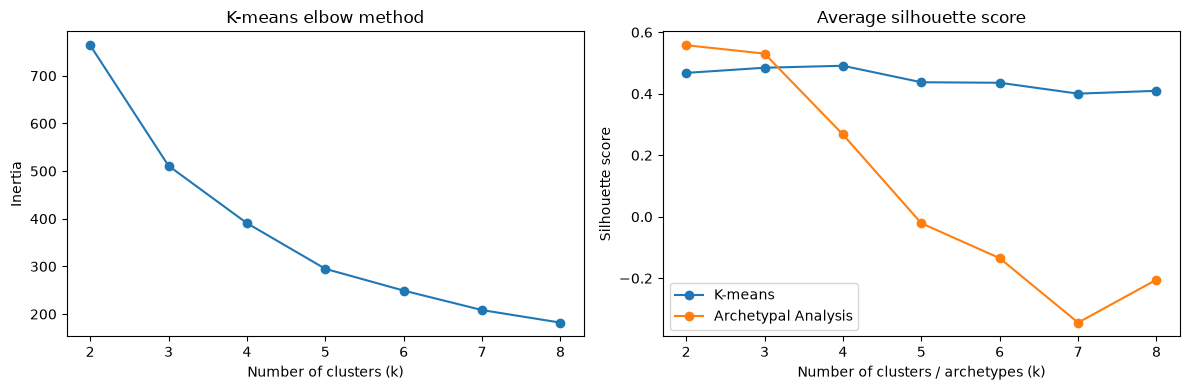

K-means silhouette scores: {2: np.float64(0.468), 3: np.float64(0.485), 4: np.float64(0.491), 5: np.float64(0.437), 6: np.float64(0.436), 7: np.float64(0.4), 8: np.float64(0.41)}
AA silhouette scores: {2: np.float64(0.558), 3: np.float64(0.531), 4: np.float64(0.268), 5: np.float64(-0.021), 6: np.float64(-0.135), 7: np.float64(-0.344), 8: np.float64(-0.205)}


In [7]:
# # 2. DIAGNOSTICS: ELBOW & SILHOUETTE SCORE Compare candidate cluster counts using inertia and average silhouette scores.
ks = range(2, 9)
inertia = []
sil_kmeans = []
sil_aa = []

for candidate_k in ks:
    kmeans_model = KMeans(
        n_clusters=candidate_k, n_init=10, random_state=42
    ).fit(X_scaled)
    inertia.append(kmeans_model.inertia_)
    sil_kmeans.append(silhouette_score(X_scaled, kmeans_model.labels_))

    aa_model = AA(n_archetypes=candidate_k, random_state=42)
    aa_model.fit(X_scaled)
    sil_aa.append(silhouette_score(X_scaled, aa_model.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(list(ks), inertia, marker='o')
ax1.set(title='K-means elbow method', xlabel='Number of clusters (k)', ylabel='Inertia')
ax2.plot(list(ks), sil_kmeans, marker='o', label='K-means')
ax2.plot(list(ks), sil_aa, marker='o', label='Archetypal Analysis')
ax2.set(title='Average silhouette score', xlabel='Number of clusters / archetypes (k)', ylabel='Silhouette score')
ax2.legend()
plt.tight_layout()
plt.show()

print('K-means silhouette scores:', dict(zip(ks, np.round(sil_kmeans, 3))))
print('AA silhouette scores:', dict(zip(ks, np.round(sil_aa, 3))))

In [8]:

# 3. FIT K-MEANS & ARCHETYPAL ANALYSIS (k = 3)
#3.1 Fit K-means on the full dataset using k selected from the diagnostics.
k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=42)
km_labels = km.fit_predict(X_scaled)

# Convert K-means centroids back to original units ($ and Mbps)
km_centers_real = pd.DataFrame(
    scaler.inverse_transform(km.cluster_centers_), columns=feature_cols
)

In [9]:

# 3.2 Fit Archetypal Analysis (AA) on Full Dataset

aa = AA(n_archetypes=k, random_state=42)
aa.fit(X_scaled)
aa_labels = aa.labels_

# Convert Archetypes back to original units ($ and Mbps)
aa_centers_real = pd.DataFrame(
    scaler.inverse_transform(aa.archetypes_), columns=feature_cols
)

In [10]:

# 4. Compare Models with Adjusted Rand Index (ARI)

ari_score = adjusted_rand_score(km_labels, aa_labels)

print(f"Adjusted Rand Index (ARI) on full dataset: {ari_score:.3f}")

print("=== CLUSTER CENTROIDS (K-Means) ===")
print(km_centers_real.round(2))
print("\n=== ARCHETYPES / EXTREMES (AA) ===")
print(aa_centers_real.round(2))
print(f"\nAdjusted Rand Index (ARI): {ari_score:.3f}")

Adjusted Rand Index (ARI) on full dataset: 0.056
=== CLUSTER CENTROIDS (K-Means) ===
   cost_nomad  internet_speed
0     1553.69            7.95
1     3556.22           16.05
2     2849.48           55.00

=== ARCHETYPES / EXTREMES (AA) ===
   cost_nomad  internet_speed
0    10117.04            2.00
1     2783.00          197.00
2      608.45            1.89

Adjusted Rand Index (ARI): 0.056


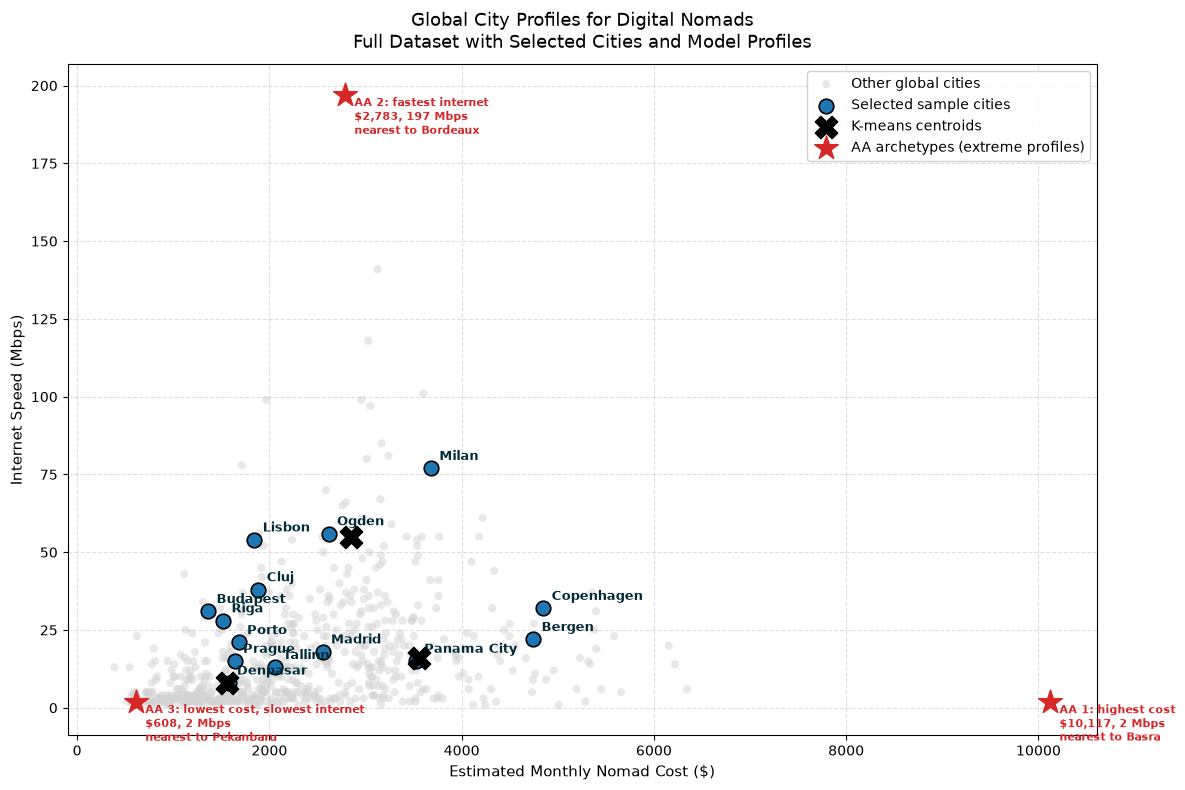

,archetype,basis,nearest_city,cost_nomad,internet_speed
0,1,highest cost,Basra,10117.035935,1.999699
1,2,fastest internet,Bordeaux,2783.000000,197.000000
2,3,"lowest cost, slowest internet",Pekanbaru,608.445926,1.894773


In [12]:
# 5. Visualizing Full Dataset with 14 Sample City Callouts

sample_names = [
    "Budapest",
    "Copenhagen",
    "Bergen",
    "Porto",
    "Lisbon",
    "Madrid",
    "Prague",
    "Tallinn",
    "Milan",
    "Riga",
    "Cluj",
    "Denpasar",
    "Panama City",
    "Ogden"
]

# Separate sample cities from remaining global cities
is_sample = X_raw.index.isin(sample_names)
sample_cities = X_raw.loc[is_sample]
bg_cities = X_raw.loc[~is_sample]

fig, ax = plt.subplots(figsize=(12, 8))

# Background layer: All global cities as faint context points
ax.scatter(
    bg_cities["cost_nomad"],
    bg_cities["internet_speed"],
    c="lightgray",
    alpha=0.5,
    s=35,
    edgecolors="none",
    label="Other global cities",
)

# Foreground layer: Highlighted sample cities
ax.scatter(
    sample_cities["cost_nomad"],
    sample_cities["internet_speed"],
    c="#1f77b4",
    s=110,
    edgecolor="black",
    linewidth=1.2,
    zorder=3,
    label="Selected sample cities",
)

# Annotate sample city labels
for city, row in sample_cities.iterrows():
  ax.annotate(
      city,
      (row["cost_nomad"], row["internet_speed"]),
      xytext=(6, 6),
      textcoords="offset points",
      fontsize=9,
      fontweight="bold",
      color="#002b36",
      zorder=4,
  )

# K-means centers
ax.scatter(
    km_centers_real["cost_nomad"],
    km_centers_real["internet_speed"],
    marker="X",
    s=260,
    c="black",
    zorder=5,
    label="K-means centroids",
)

# AA archetypes are profiles; identify their nearest real cities for context.
aa_nearest_positions = [
    np.linalg.norm(X_scaled - archetype, axis=1).argmin()
    for archetype in aa.archetypes_
]
aa_nearest_cities = X_raw.index[aa_nearest_positions]
aa_cost_max = aa_centers_real["cost_nomad"].idxmax()
aa_cost_min = aa_centers_real["cost_nomad"].idxmin()
aa_speed_max = aa_centers_real["internet_speed"].idxmax()
aa_speed_min = aa_centers_real["internet_speed"].idxmin()

def aa_extreme_basis(archetype_index):
    basis = []
    if archetype_index == aa_cost_max:
        basis.append("highest cost")
    if archetype_index == aa_cost_min:
        basis.append("lowest cost")
    if archetype_index == aa_speed_max:
        basis.append("fastest internet")
    if archetype_index == aa_speed_min:
        basis.append("slowest internet")
    return ", ".join(basis)

ax.scatter(
    aa_centers_real["cost_nomad"],
    aa_centers_real["internet_speed"],
    marker="*",
    s=320,
    c="#d62728",
    zorder=5,
    label="AA archetypes (extreme profiles)",
)
for archetype_number, (archetype_index, row, nearest_city) in enumerate(
    zip(aa_centers_real.index, aa_centers_real.itertuples(index=False), aa_nearest_cities),
    start=1,
):
    ax.annotate(
        f"AA {archetype_number}: {aa_extreme_basis(archetype_index)}\n"
        f"${row.cost_nomad:,.0f}, {row.internet_speed:.0f} Mbps\n"
        f"nearest to {nearest_city}",
        (row.cost_nomad, row.internet_speed),
        xytext=(7, -28),
        textcoords="offset points",
        fontsize=8,
        color="#d62728",
        fontweight="bold",
        zorder=6,
    )

ax.set_xlabel("Estimated Monthly Nomad Cost ($)", fontsize=11)
ax.set_ylabel("Internet Speed (Mbps)", fontsize=11)
ax.set_title(
    "Global City Profiles for Digital Nomads\nFull Dataset with Selected Cities and Model Profiles",
    fontsize=13,
    pad=12,
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.show()

pd.DataFrame({
    "archetype": range(1, len(aa_nearest_cities) + 1),
    "basis": [aa_extreme_basis(index) for index in aa_centers_real.index],
    "nearest_city": aa_nearest_cities,
    "cost_nomad": aa_centers_real["cost_nomad"].values,
    "internet_speed": aa_centers_real["internet_speed"].values,
})